# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Устройство: CUDA, Tesla T4 (Google Colab). Ветка: targeted (5.2). Выполнены разделы 1–6 и бонусы 7.1–7.5; нерешённых выбранных задач нет. `FAST_MODE=False`.

In [1]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit
import os

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [3]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.3', '7.4', '7.5'}        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [4]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [5]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [86]:
datasets.FashionMNIST.mirrors = ['https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/']

def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # ваш код
    B, C_in, H, W = x.shape
    C_out, c_group, kh, kw = weight.shape
    if groups <= 0 or C_in % groups or C_out % groups or c_group != C_in // groups:
        raise ValueError('Incompatible groups/channels')
    ho, wo = conv_output_shape((H,W), (kh,kw), stride, padding, dilation)
    cols = F.unfold(x, (kh,kw), dilation=dilation, padding=padding, stride=stride)
    cols = cols.reshape(B, groups, c_group*kh*kw, ho*wo)
    weights = weight.reshape(groups, C_out//groups, c_group*kh*kw)
    out = torch.einsum('gok,bgkl->bgol', weights, cols).reshape(B,C_out,ho,wo)

    return out if bias is None else out + bias[None,:,None,None]

In [7]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [8]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** Для ядер 3×3, 5×5 и 7×7 я получил увеличение числа элементов в 9, 25 и 49 раз. При stride=1 и padding=k//2 число пространственных позиций сохраняется, поэтому cols/x=k². Память im2col растёт квадратично с размером ядра. FFT заменяет пространственную свёртку умножением спектров, что может быть выгодно для больших ядер, хотя преобразования и спектральные буферы тоже требуют времени и памяти.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [9]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding, ctx.has_bias = stride, padding, bias is not None
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        # ваш код
        kh, kw = weight.shape[-2:]
        op = tuple(x.shape[2+i] - ((grad_out.shape[2+i]-1)*s-2*p+k)
                   for i,k in enumerate((kh,kw)))
        grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=op)
        cols = F.unfold(x,(kh,kw),padding=p,stride=s)
        grad_w = torch.einsum('bol,bkl->ok',grad_out.flatten(2),cols).reshape_as(weight)
        grad_b = grad_out.sum((0,2,3)) if ctx.has_bias else None
        return grad_x, grad_w, grad_b, None, None

In [10]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** В качестве примера я взял H=7 и H=8: в обоих случаях H_out=4. Базовый размер после conv_transpose2d равен (4−1)·2−2·1+3=7, поэтому output_padding должен быть 0 и 1 соответственно. Это выбор формы сопряжённого оператора, а не восстановление исходного x без потерь.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [11]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [85]:
def empirical_rf(model, in_channels=1, size=96):
    # ваш код
    p = next(model.parameters(), None)
    kw = {} if p is None else dict(device=p.device,dtype=p.dtype)
    x = torch.randn(1,in_channels,size,size,requires_grad=True,**kw)
    out=model(x)
    g,=torch.autograd.grad(out[0,:,out.shape[2]//2,out.shape[3]//2].sum(),x)
    coords=(g[0].abs().sum(0)>0).nonzero()
    if len(coords)==0:
        return (0,0)
    return tuple((coords.max(0).values-coords.min(0).values+1).tolist())

In [13]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** Для проверки я использовал положительные усредняющие ядра без нелинейностей: они не отсекают пути и не дают градиентам взаимно сокращаться. MaxPool передаёт градиент только через максимум каждого окна, поэтому носитель зависит от входа. При этом bounding box может остаться таким же, даже если часть пикселей внутри него имеет нулевой градиент.

Измеренные bounding boxes (AvgPool / MaxPool): {'conv3x3 x4': {'avg': (9, 9), 'maxpool': (9, 9)}, 'conv-pool': {'avg': (18, 18), 'maxpool': (18, 18)}, 'strided': {'avg': (17, 17), 'maxpool': (17, 17)}, 'dilated': {'avg': (15, 15), 'maxpool': (15, 15)}}.

В данном прогоне bounding box с MaxPool совпал с AvgPool (18×18 для conv-pool). Это не означает равенства носителя или величин градиентов внутри рамки: MaxPool всё равно оставляет только выбранные пути.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [84]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    # ваш код
    p=next(model.parameters(),None)
    kw={} if p is None else dict(device=p.device,dtype=p.dtype)
    mass=torch.zeros(size,size,**kw)

    for _ in range(n_inputs):
        x=torch.randn(1,in_channels,size,size,requires_grad=True,**kw)
        out=model(x)
        g,=torch.autograd.grad(out[0,:,out.shape[2]//2,out.shape[3]//2].sum(),x)
        mass+=g.detach().abs().sum((0,1))

    rows=mass.sum(1)
    if rows.sum()==0:return 0.0
    prob=rows/rows.sum()
    pos=torch.arange(size,device=prob.device,dtype=prob.dtype)
    mean=(pos*prob).sum()
    return ((pos-mean).square()*prob).sum().sqrt().item()

In [15]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [16]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


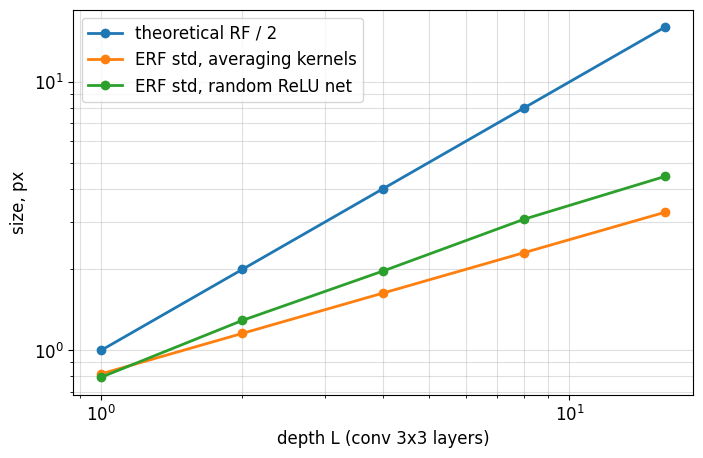

In [17]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** Для усредняющей сети я получил $\sigma_{\mathrm{ERF}}=\sqrt{2L/3}$: наклон на log-log графике равен 0.5. Теоретический RF равен $r_L=2L+1$, а его радиус $(r_L-1)/2=L$ растёт с наклоном 1. Поэтому отношение ERF к теоретическому радиусу уменьшается как $L^{-1/2}$.

Для случайной ReLU-сети измеренный наклон составляет примерно 0.62. На рассмотренных глубинах ERF растёт быстрее, чем у усредняющей сети, но медленнее теоретического радиуса. Отношение ERF к теоретическому радиусу также уменьшается.

| Глубина L | ERF std, усредняющая сеть, px | ERF std, ReLU, px |
|---:|---:|---:|
| 1 | 0.82 | 0.79 |
| 2 | 1.15 | 1.29 |
| 4 | 1.63 | 1.97 |
| 8 | 2.31 | 3.08 |
| 16 | 3.27 | 4.44 |

Я использовал модуль градиента: ReLU отсекает часть путей, а случайные веса допускают взаимные сокращения вкладов до взятия модуля. Результаты получены для одного seed и пяти глубин, поэтому я не переношу измеренный наклон на все обученные сети.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [18]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        # ваш код
        super().__init__()
        self.eps,self.momentum=eps,momentum
        self.weight=nn.Parameter(torch.ones(num_features))
        self.bias=nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean',torch.zeros(num_features))
        self.register_buffer('running_var',torch.ones(num_features))
        self.register_buffer('num_batches_tracked',torch.tensor(0,dtype=torch.long))

    def forward(self,x):
        # ваш код
        if x.ndim!=4:raise ValueError('Expected NCHW input')
        if self.training:
            n=x.numel()//x.shape[1]
            if n<=1:raise ValueError('More than one value per channel is required')
            mean=x.mean((0,2,3)); var=x.var((0,2,3),unbiased=False)
            with torch.no_grad():
                self.num_batches_tracked.add_(1)
                m=1/self.num_batches_tracked.item() if self.momentum is None else self.momentum
                self.running_mean.lerp_(mean.detach(),m)
                self.running_var.lerp_(var.detach()*n/(n-1),m)
        else:mean,var=self.running_mean,self.running_var
        shape=(1,-1,1,1)
        return (x-mean.view(shape))*torch.rsqrt(var.view(shape)+self.eps)*self.weight.view(shape)+self.bias.view(shape)

In [19]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** В своей реализации я нормировал батч по смещённой дисперсии, а running_var обновлял несмещённой оценкой. Первая описывает фактический второй центральный момент текущего батча, вторая оценивает дисперсию распределения и включает поправку n/(n−1). При B=4,H=W=5 имею n=100: множитель 100/99≈1.0101, то есть +1.01%. При B=2,H=W=1 имею n=2: множитель 2, то есть +100%. Для стандартного отклонения соответствующие множители равны √(100/99)≈1.0050 и √2≈1.4142.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** Я подставил выход свёртки в аффинное преобразование BN и обозначил a_o=γ_o/√(running_var_o+ε). Получил W′_o=a_oW_o и b′_o=β_o+a_o(b_o−running_mean_o). Если у свёртки нет bias, беру b_o=0. В eval эти коэффициенты фиксированы; при слиянии я создаю новый модуль и не меняю исходные веса.

In [20]:
@torch.no_grad()
def fuse_conv_bn(conv,bn):
    # ваш код
    if conv.training or bn.training:raise ValueError('Fusion requires eval mode')
    fused=nn.Conv2d(conv.in_channels,conv.out_channels,conv.kernel_size,
                    stride=conv.stride,padding=conv.padding,dilation=conv.dilation,
                    groups=conv.groups,bias=True,padding_mode=conv.padding_mode,
                    device=conv.weight.device,dtype=conv.weight.dtype)
    scale=bn.weight/torch.sqrt(bn.running_var+bn.eps)
    bias=conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)
    fused.weight.copy_(conv.weight*scale[:,None,None,None])
    fused.bias.copy_(bn.bias+(bias-bn.running_mean)*scale)
    return fused.eval()


def fuse_sequential(seq):
    # ваш код
    if seq.training:raise ValueError('Fusion requires eval mode')
    mods=list(seq.children());result=[];i=0
    while i<len(mods):
        if i+1<len(mods) and isinstance(mods[i],nn.Conv2d) and isinstance(mods[i+1],nn.BatchNorm2d):
            result.append(fuse_conv_bn(mods[i],mods[i+1]));i+=2
        else:result.append(copy.deepcopy(mods[i]));i+=1
    return nn.Sequential(*result).eval()

In [21]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [22]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [23]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 257.2 ms   fused: 268.4 ms   speedup 0.96x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** Я выполнял слияние только в eval: в train среднее и дисперсия зависят от текущего батча, поэтому их нельзя включить в один фиксированный набор весов для всех входов. Fusion убирает отдельное поканальное преобразование и промежуточную запись/чтение активаций.

На CPU я измерил 257.2 ms для Conv+BN и 268.4 ms после fusion. Отношение времени Conv+BN к fused составило 0.96×. В этом прогоне ускорения я не получил: fused-вариант оказался примерно на 4.4% медленнее.

Я брал минимум пяти повторов по пять вызовов. Удаление отдельного BatchNorm не гарантирует ускорения: результат зависит от размеров тензоров, устройства, backend и условий замера. Причину замедления по этому эксперименту я установить не могу и не делаю общего вывода, что fusion всегда работает медленнее.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Из E[ReLU(h)²]=Var(h)/2 для симметричной преактивации я получил v=2/n для сохранения Var преактиваций — это Kaiming. В линейном режиме tanh≈h нужен v=1/n, то есть Xavier при равных fan_in и fan_out. У default U(−1/√n,1/√n) дисперсия v=1/(3n): второй момент уменьшается в 6 раз за слой, а характерное std — примерно в √6 раз, с множителем 1/√6≈0.4082. Здесь я использовал предположения о независимости и симметрии; центрированная дисперсия ReLU отличается от второго момента.

In [24]:
INITS = {
    'N(0, 0.01^2)':lambda w:nn.init.normal_(w,std=0.01),
    'PyTorch default':lambda w:nn.init.kaiming_uniform_(w,a=math.sqrt(5)),
    'Xavier':nn.init.xavier_normal_,
    'Kaiming':lambda w:nn.init.kaiming_normal_(w,nonlinearity='relu'),
}

@torch.no_grad()
def activation_stds(init,act,depth=50,width=256,n=1024,seed=0):
    # ваш код
    torch.manual_seed(seed)
    h=torch.randn(n,width)
    stds=[]
    for _ in range(depth):
        layer=nn.Linear(width,width,bias=False)
        init(layer.weight)
        h=act(layer(h))
        stds.append(h.std().item())
    return stds

In [25]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.882


np.float64(0.4100027508284732)

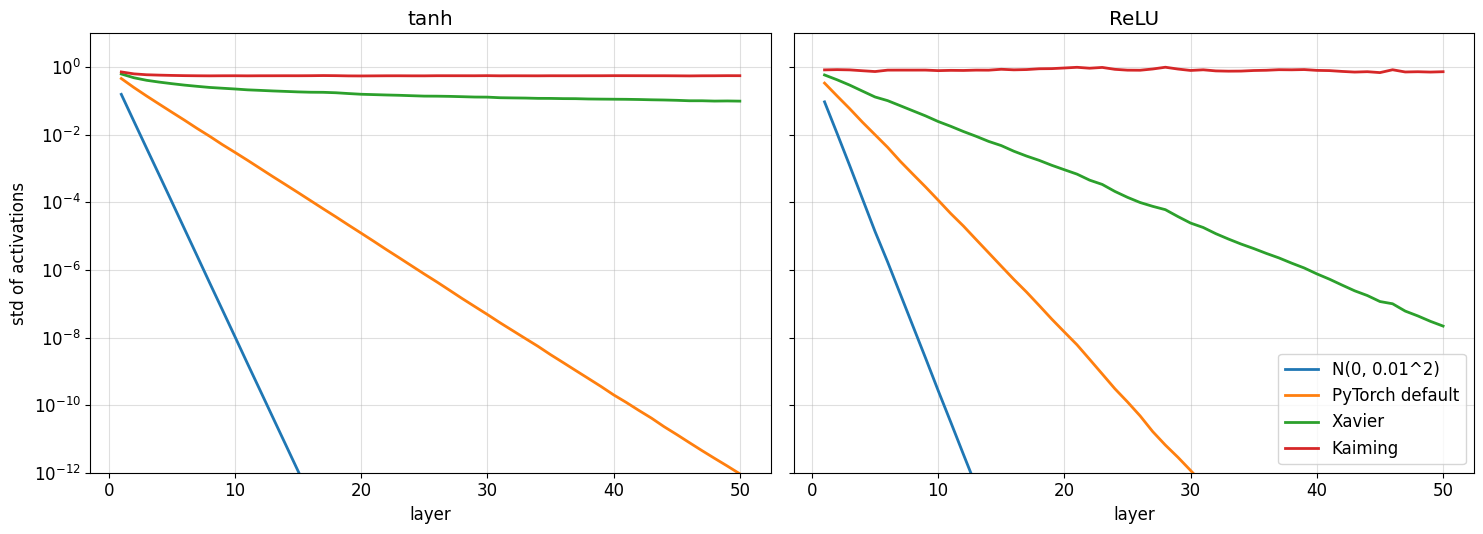

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** На 50 слоях я получил отношения std последнего слоя к первому:

| Инициализация | tanh | ReLU |
|---|---:|---:|
| N(0, 0.01²) | 9.97×10⁻⁴⁰ | 0 (underflow) |
| PyTorch default | 2.01×10⁻¹² | 1.06×10⁻¹⁹ |
| Xavier | 0.157 | 3.72×10⁻⁸ |
| Kaiming | 0.774 | 0.882 |

В моём опыте Kaiming+ReLU и Kaiming+tanh сохранили масштаб порядка единицы. Xavier+tanh соответствует сохранению дисперсии в линейном режиме, но при первоначальном насыщении tanh std заметно снизилось. Для default+ReLU я измерил множитель 0.410 за слой, близкий к теоретическому 1/√6≈0.408. Остальные варианты с ReLU и малые/default веса с tanh приводят к затуханию.

ResNet отличается от этого MLP: BatchNorm контролирует масштаб, residual-связи дают короткие пути сигналу и градиенту, а параметры меняются при обучении. Поэтому затухание в таком MLP не означает, что любая сеть с default-инициализацией не сможет обучаться.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [27]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self,params,lr=1e-3,betas=(0.9,0.999),eps=1e-8,weight_decay=1e-2,bias_correction=True):
        # ваш код
        if lr<0 or eps<0 or weight_decay<0 or not all(0<=b<1 for b in betas):
            raise ValueError('Invalid optimizer hyperparameters')
        super().__init__(params,dict(lr=lr,betas=betas,eps=eps,weight_decay=weight_decay,bias_correction=bias_correction))

    @torch.no_grad()
    def step(self):
        # ваш код
        for group in self.param_groups:
            beta1,beta2=group['betas']
            for p in group['params']:
                if p.grad is None:continue
                g=p.grad
                if g.is_sparse:raise RuntimeError('Sparse gradients are not supported')
                state=self.state[p]
                if not state:
                    state.update(step=0,exp_avg=torch.zeros_like(p),exp_avg_sq=torch.zeros_like(p))
                state['step']+=1
                m,v=state['exp_avg'],state['exp_avg_sq']
                p.mul_(1-group['lr']*group['weight_decay'])
                m.mul_(beta1).add_(g,alpha=1-beta1)
                v.mul_(beta2).addcmul_(g,g,value=1-beta2)
                t=state['step']
                c1=1-beta1**t if group['bias_correction'] else 1
                c2=1-beta2**t if group['bias_correction'] else 1
                denom=(v/c2).sqrt().add_(group['eps'])
                p.addcdiv_(m,denom,value=-group['lr']/c1)

In [28]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [29]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


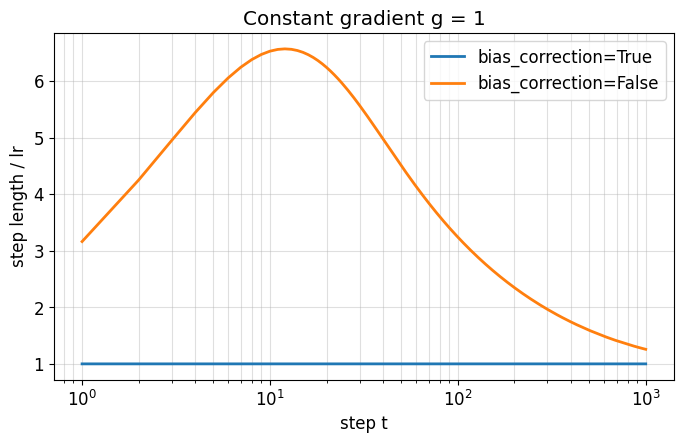

In [30]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** Для постоянного g_t=1 я получил m_t=1−β₁^t и v_t=1−β₂^t. Без bias correction длина шага равна η(1−β₁^t)/(√(1−β₂^t)+ε). При β₁=0.9 и β₂=0.999 первый шаг примерно 3.16η, а с correction — примерно η. Увеличенный и меняющийся ранний шаг может вывести параметры из стабильной области. В этом опыте я отключил weight decay, чтобы сравнивать только bias correction.

Шаг/lr без correction при t=1,10,100,1000: [3.16, 6.52, 3.24, 1.25]; максимум 6.56 при t=12.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [31]:
def cosine_lr(step,total_steps,min_ratio=0.0):
    # ваш код
    if total_steps<=0:raise ValueError('total_steps must be positive')
    return min_ratio+(1-min_ratio)*(1+math.cos(math.pi*min(1,step/total_steps)))/2

In [32]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

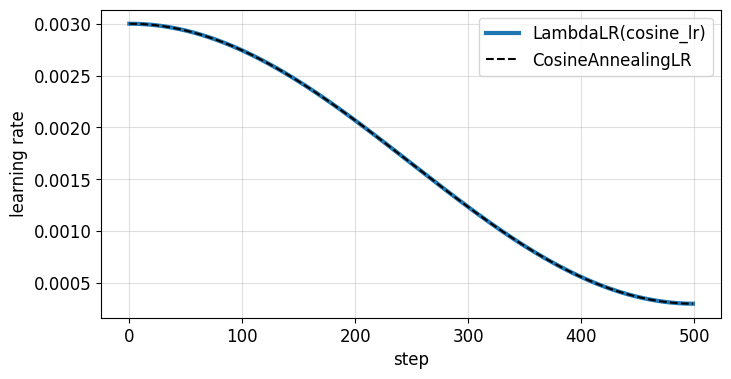

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Я уменьшал общий lr, потому что адаптивный AdamW регулирует относительный масштаб координат, но не устраняет шум минибатчей. Снижение lr уменьшает колебания и помогает стабилизироваться около минимума. При постоянном ненулевом шаге стохастический метод обычно колеблется в окрестности минимума. В проверке я получил lr₀=0.003 и lr_T=0.0003 при T=500 и r=0.1.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [34]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [54:14<00:00, 52.4kB/s]


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

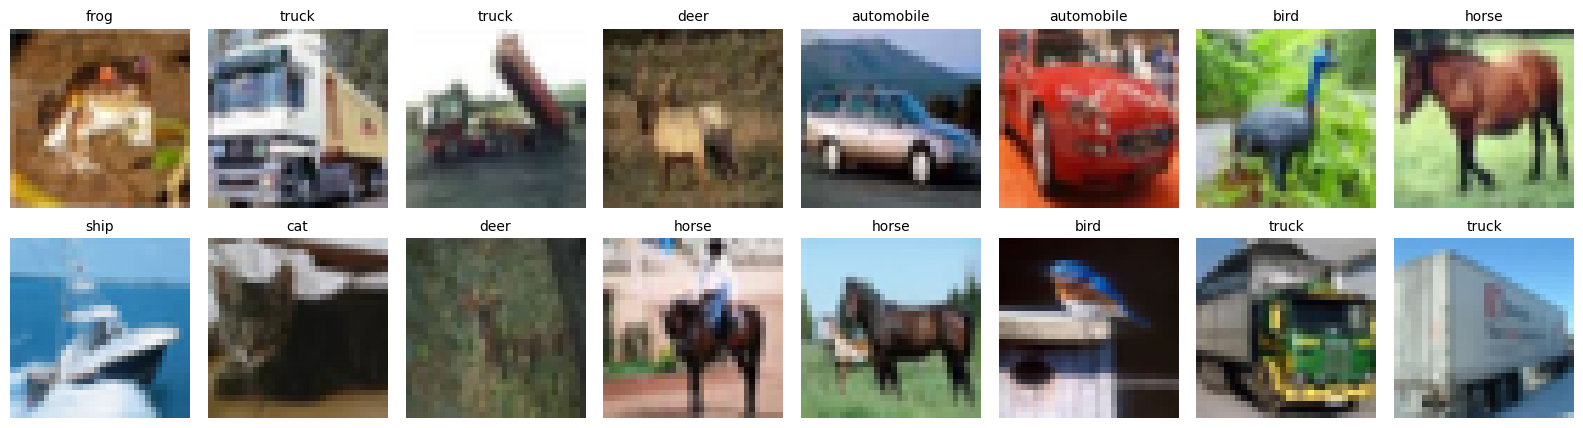

In [35]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [36]:
def conv3x3(c_in,c_out,stride=1,separable=False):
    # ваш код
    if separable:
        return nn.Sequential(nn.Conv2d(c_in,c_in,3,stride=stride,padding=1,groups=c_in,bias=False),
                             nn.Conv2d(c_in,c_out,1,bias=False))
    return nn.Conv2d(c_in,c_out,3,stride=stride,padding=1,bias=False)

class Block(nn.Module):
    def __init__(self,c_in,c_out,stride=1,residual=True,separable=False):
        # ваш код
        super().__init__()
        self.residual=residual
        self.conv1=conv3x3(c_in,c_out,stride,separable)
        self.bn1=nn.BatchNorm2d(c_out)
        self.conv2=conv3x3(c_out,c_out,1,separable)
        self.bn2=nn.BatchNorm2d(c_out)
        if residual:
            self.shortcut=nn.Identity() if stride==1 and c_in==c_out else nn.Sequential(
                nn.Conv2d(c_in,c_out,1,stride=stride,bias=False),nn.BatchNorm2d(c_out))
    def forward(self,x):
        # ваш код
        out=self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual:out=out+self.shortcut(x)
        return F.relu(out)

class ResNetCIFAR(nn.Module):
    def __init__(self,depth=20,residual=True,separable=False,widths=(16,32,64),n_classes=10):
        # ваш код
        super().__init__()
        assert (depth-2)%6==0 and depth>=8
        n=(depth-2)//6
        self.stem=nn.Sequential(nn.Conv2d(3,widths[0],3,padding=1,bias=False),nn.BatchNorm2d(widths[0]),nn.ReLU())
        layers=[];c=widths[0]
        for stage,w in enumerate(widths):
            for b in range(n):
                stride=2 if stage>0 and b==0 else 1
                layers.append(Block(c,w,stride,residual,separable));c=w
        self.blocks=nn.Sequential(*layers)
        self.head=nn.Linear(widths[-1],n_classes)
    def forward(self,x):
        # ваш код
        return self.head(self.blocks(self.stem(x)).mean((2,3)))

In [37]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [38]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82

def train_cifar(model,epochs,lr,weight_decay=0.05,batch_size=256,log=True):
    # ваш код
    model=model.to(device)
    history=dict(train_loss=[],test_acc=[])
    start=time.time()
    groups=[dict(params=[p for p in model.parameters() if p.ndim>1],weight_decay=weight_decay),
            dict(params=[p for p in model.parameters() if p.ndim<=1],weight_decay=0.)]
    opt=MyAdamW(groups,lr=lr)
    total=epochs*math.ceil(len(X_train)/batch_size)
    sch=torch.optim.lr_scheduler.LambdaLR(opt,lambda t:cosine_lr(t,total))
    for epoch in range(epochs):
        model.train();loss_sum=0.
        for x,y in iterate_batches(X_train,Y_train,batch_size):
            opt.zero_grad(set_to_none=True)
            loss=F.cross_entropy(model(normalize(x)),y)
            loss.backward();opt.step();sch.step()
            loss_sum+=loss.item()*len(x)
        history['train_loss'].append(loss_sum/len(X_train))
        history['test_acc'].append(accuracy(predict_logits(model,X_test,transform=normalize),Y_test))
        if log:print(f'epoch {epoch+1}/{epochs}: loss={history["train_loss"][-1]:.4f}, test={history["test_acc"][-1]:.4f}, seconds={time.time()-start:.1f}',flush=True)
    model.eval();model.zero_grad(set_to_none=True)
    return history

In [39]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch 1/20: loss=1.4434, test=0.5074, seconds=17.3
epoch 2/20: loss=0.9609, test=0.5543, seconds=32.4
epoch 3/20: loss=0.7644, test=0.6657, seconds=47.9
epoch 4/20: loss=0.6433, test=0.6793, seconds=63.6
epoch 5/20: loss=0.5641, test=0.7689, seconds=79.7
epoch 6/20: loss=0.4919, test=0.7554, seconds=96.2
epoch 7/20: loss=0.4308, test=0.7565, seconds=113.0
epoch 8/20: loss=0.3721, test=0.7840, seconds=129.9
epoch 9/20: loss=0.3213, test=0.8012, seconds=146.5
epoch 10/20: loss=0.2667, test=0.7998, seconds=163.0
epoch 11/20: loss=0.2125, test=0.8104, seconds=179.6
epoch 12/20: loss=0.1607, test=0.7936, seconds=196.2
epoch 13/20: loss=0.1119, test=0.8148, seconds=212.9
epoch 14/20: loss=0.0721, test=0.8193, seconds=229.7
epoch 15/20: loss=0.0433, test=0.8267, seconds=246.4
epoch 16/20: loss=0.0261, test=0.8243, seconds=263.2
epoch 17/20: loss=0.0178, test=0.8266, seconds=279.9
epoch 18/20: loss=0.0144, test=0.8269, seconds=296.7
epoch 19/20: loss=0.0121, test=0.8262, seconds=313.4
epoch 20

{'train acc': 0.9997999668121338, 'test acc': 0.8252999782562256}

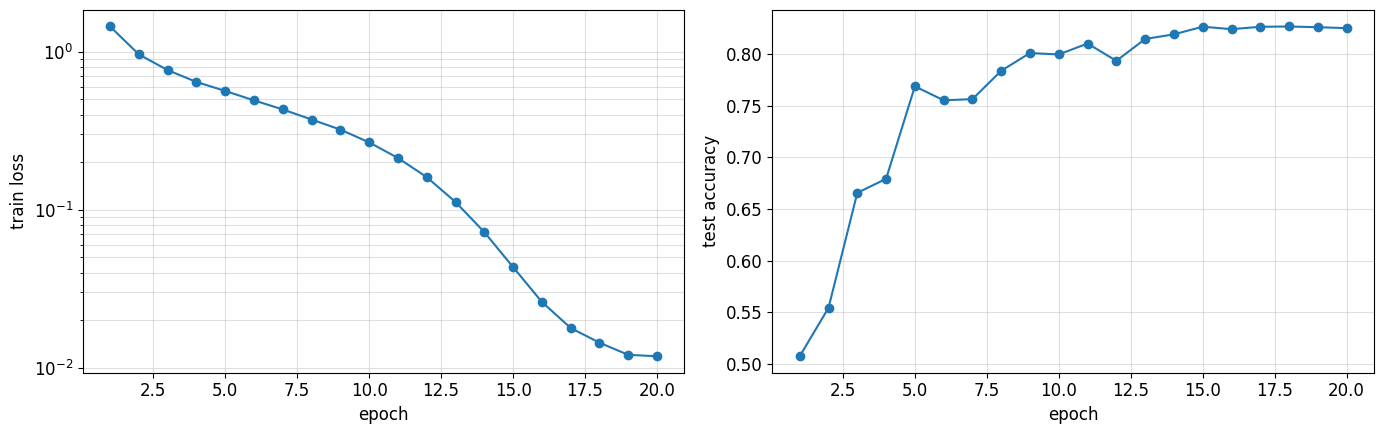

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** В конце обучения я получил train accuracy 99.98% на первых 10 000 train-объектах и test accuracy 82.5% на полном test наборе. Разрыв составил 17.45 п.п. Train loss усреднялся по всему train набору.

На последних пяти эпохах train loss снизился с 0.0261 до 0.0118, а test accuracy изменилась с 82.4% до 82.5%. При уходе cosine lr к нулю обновления становятся небольшими: train loss продолжает снижаться, но test accuracy практически вышла на плато. Я связываю разрыв train/test с ограниченным обобщением модели, а не с тем, что оптимизация ещё не снизила train loss.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [41]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [42]:
# ваш код
ablation={}
for name,cfg in ABLATIONS.items():
    set_seed(0);model=ResNetCIFAR(**cfg);started=time.perf_counter()
    hist=train_cifar(model,ABL_EPOCHS,LR)
    ablation[name]=dict(params=n_params(model),train_acc=accuracy(predict_logits(model,X_train[:10000],transform=normalize),Y_train[:10000]),
                        test_acc=hist['test_acc'][-1],minutes=(time.perf_counter()-started)/60,history=hist)
    del model
print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name,res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

epoch 1/10: loss=1.7230, test=0.3128, seconds=15.8
epoch 2/10: loss=1.3846, test=0.5268, seconds=31.7
epoch 3/10: loss=1.0992, test=0.6088, seconds=47.5
epoch 4/10: loss=0.9092, test=0.6194, seconds=63.4
epoch 5/10: loss=0.7814, test=0.6962, seconds=79.2
epoch 6/10: loss=0.6674, test=0.7433, seconds=95.0
epoch 7/10: loss=0.5804, test=0.7681, seconds=110.8
epoch 8/10: loss=0.5092, test=0.7874, seconds=126.6
epoch 9/10: loss=0.4554, test=0.7934, seconds=142.4
epoch 10/10: loss=0.4281, test=0.7915, seconds=158.2
epoch 1/10: loss=1.9328, test=0.2552, seconds=47.7
epoch 2/10: loss=1.7868, test=0.3241, seconds=95.4
epoch 3/10: loss=1.6469, test=0.3628, seconds=143.1
epoch 4/10: loss=1.5339, test=0.3587, seconds=190.7
epoch 5/10: loss=1.4345, test=0.4586, seconds=238.5
epoch 6/10: loss=1.3301, test=0.4961, seconds=286.3
epoch 7/10: loss=1.2423, test=0.5209, seconds=334.2
epoch 8/10: loss=1.1486, test=0.5658, seconds=382.1
epoch 9/10: loss=1.0783, test=0.5904, seconds=429.9
epoch 10/10: loss=1

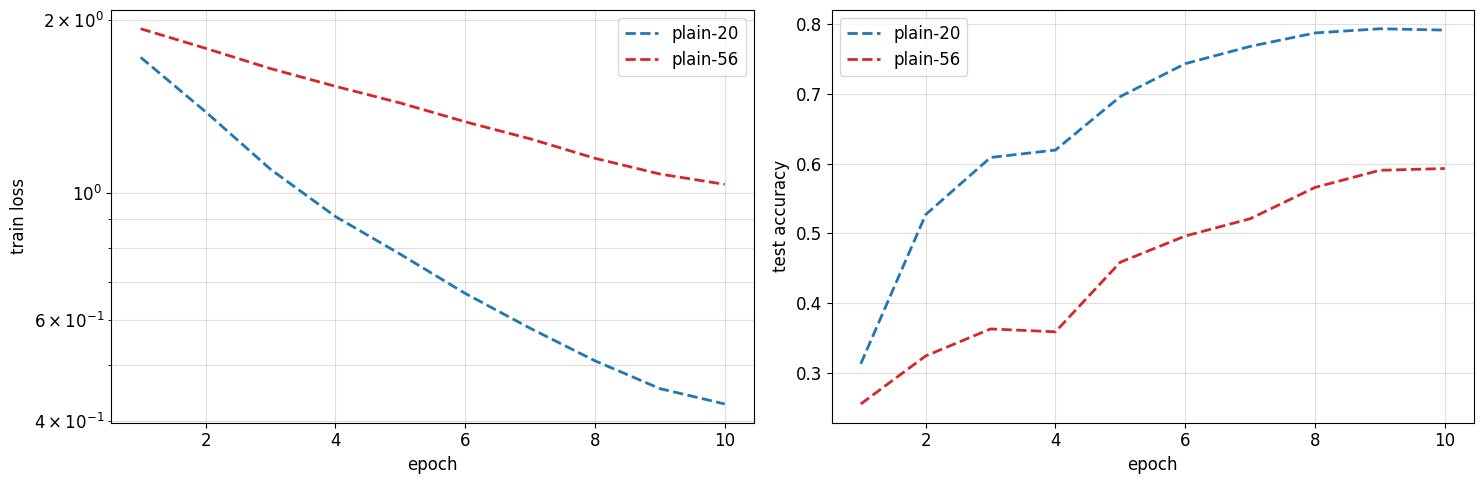

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** Я сравнил plain-20 и plain-56 при одинаковом бюджете в 10 эпох.

| Модель | Final train loss | Train accuracy¹ | Test accuracy |
|---|---:|---:|---:|
| plain-20 | 0.4281 | 87.14% | 79.15% |
| plain-56 | 1.0344 | 62.94% | 59.29% |

¹ На первых 10 000 train-объектах.

У более глубокой сети выше train loss и ниже и train, и test accuracy. Это указывает на трудности оптимизации; одним переобучением наблюдение объяснить нельзя, поскольку тогда ожидалась бы высокая train accuracy при худшей test accuracy. Следующим контролем я бы повторил обе сети с тем же протоколом и тремя заранее выбранными seed, сравнив средние и разброс train loss. По одному seed я не делаю вывода, что plain-56 хуже при любых настройках.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [44]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:00<00:00, 399MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 63.2MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 296MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.14MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [45]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [46]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [47]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.918, 'FGSM, eps=0.1': 0.071, 'PGD-20, eps=0.1': 0.005}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [48]:
def pgd_l2(model,x,y,eps,alpha,steps):
    # ваш код
    x=x.detach();adv=x.clone()
    for _ in range(steps):
        adv.requires_grad_(True)
        with torch.enable_grad():g,=torch.autograd.grad(F.cross_entropy(model(adv),y),adv)
        norm=g.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1,1,1,1)
        delta=adv.detach()+alpha*g/norm-x
        scale=(eps/delta.flatten(1).norm(dim=1).clamp_min(1e-12)).clamp(max=1).view(-1,1,1,1)
        adv=(x+delta*scale).clamp(0,1).detach()
    return adv.detach()

In [49]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.922; маленькое падение требует диагностики.


(0.922, 0.0)

In [50]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.918, 0.5: 0.447, 1.0: 0.08, 1.5: 0.009, 2.0: 0.0, 3.0: 0.0, 4.0: 0.0},
 0.005)

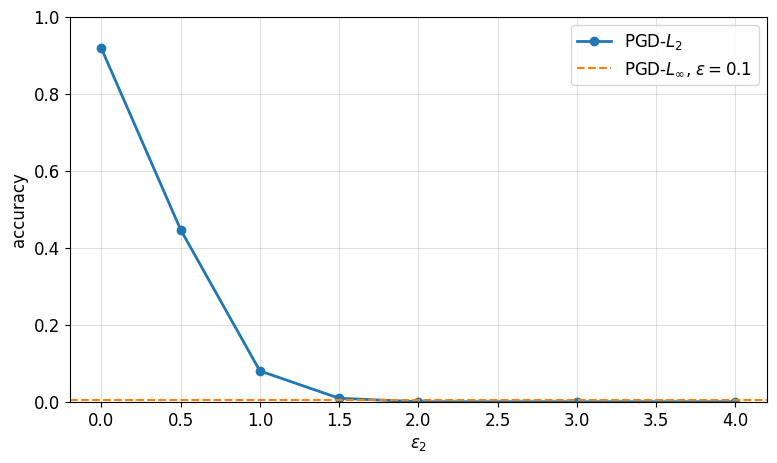

In [51]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.004


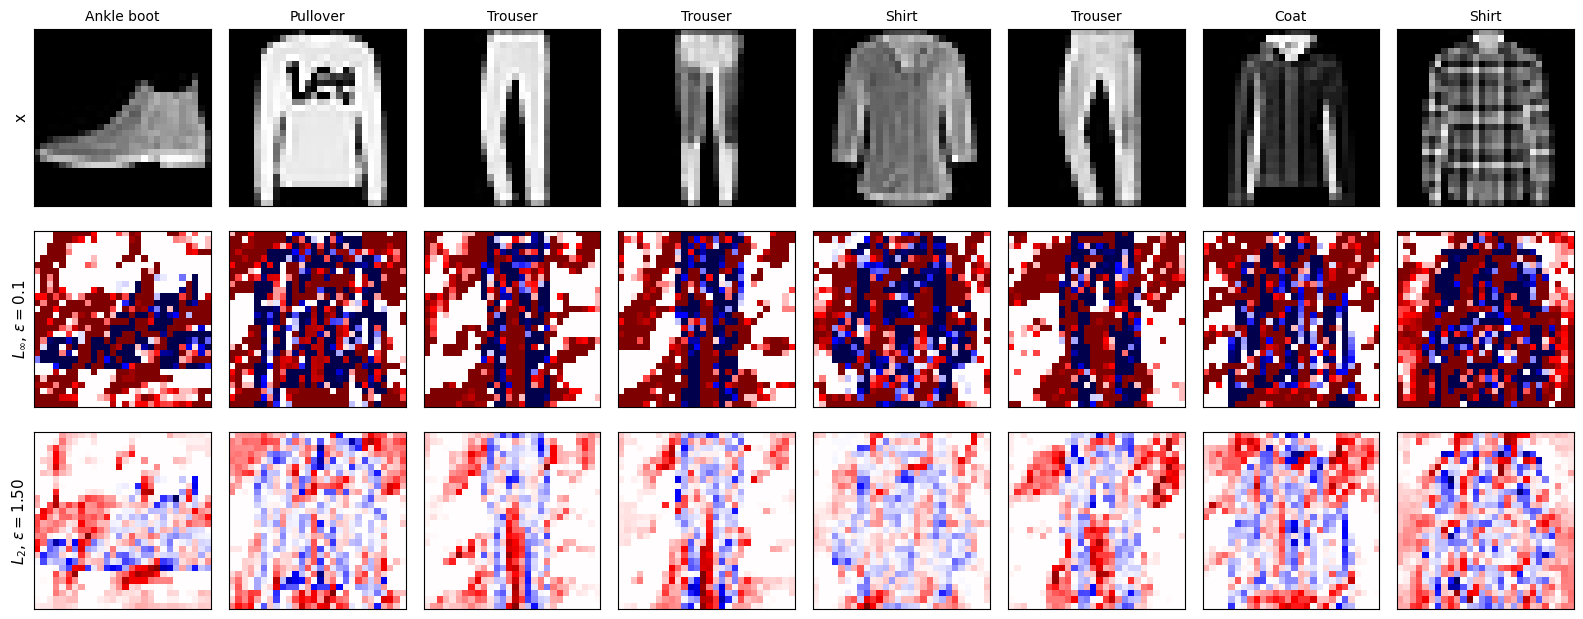

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.108
$L_2$, $\varepsilon=1.50$    L_inf = 0.250   L_2 = 1.492


In [52]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближайшей точкой сетки я получил ε₂=1.5: accuracy под L₂-PGD равна 1.0%, а под L∞-PGD при ε=0.1 — 0.6%. Остаточный разрыв равен 0.4 п.п.; совпадение по конечной сетке не означает строго равную силу атак.

Для восьми показанных изображений средняя L₂-норма L∞-возмущения равна 2.108, а L∞-норма — 0.100. У L₂-возмущения средние нормы равны 1.492 и 0.250 соответственно. L₂-ограничение допускает большие локальные сдвиги отдельных пикселей.

На картах я вижу, что L∞-возмущение широко распределено и часто достигает предела по модулю. L₂-возмущение более неоднородно: заметны локальные полосы возле штанин, деталей одежды и нижней части ботинка. Это согласуется с шагом по нормированному градиенту: сильнее меняются пиксели с большим модулем его компоненты. При этом возмущение есть и на фоне

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [53]:
if ATTACK_TRACK=='targeted':
    def pgd_targeted(model,x,target,eps,alpha,steps):
        # ваш код
        x=x.detach();adv=(x+torch.empty_like(x).uniform_(-eps,eps)).clamp(0,1)
        for _ in range(steps):
            adv.requires_grad_(True)
            with torch.enable_grad():g,=torch.autograd.grad(F.cross_entropy(model(adv),target),adv)
            adv=adv.detach()-alpha*g.sign()
            adv=torch.clamp(adv,min=x-eps,max=x+eps).clamp(0,1).detach()
        return adv.detach()

    def targeted_success_matrix(model,x,y,eps,steps=20,n_classes=10):
        # ваш код
        model.eval();S=torch.full((n_classes,n_classes),float('nan'))
        for s in range(n_classes):
            xs=x[y==s]
            if len(xs)==0:continue
            for t in range(n_classes):
                if s==t:continue
                hits=0
                for start in range(0,len(xs),128):
                    batch=xs[start:start+128]
                    target=torch.full((len(batch),),t,device=y.device,dtype=torch.long)
                    adv=pgd_targeted(model,batch,target,eps,2.5*eps/max(1,steps),steps)
                    with torch.no_grad():hits+=(model(adv).argmax(1)==t).sum().item()
                S[s,t]=hits/len(xs)
        return S

In [54]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.761; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.06 0.03 0.89 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.06 0.   0.75 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


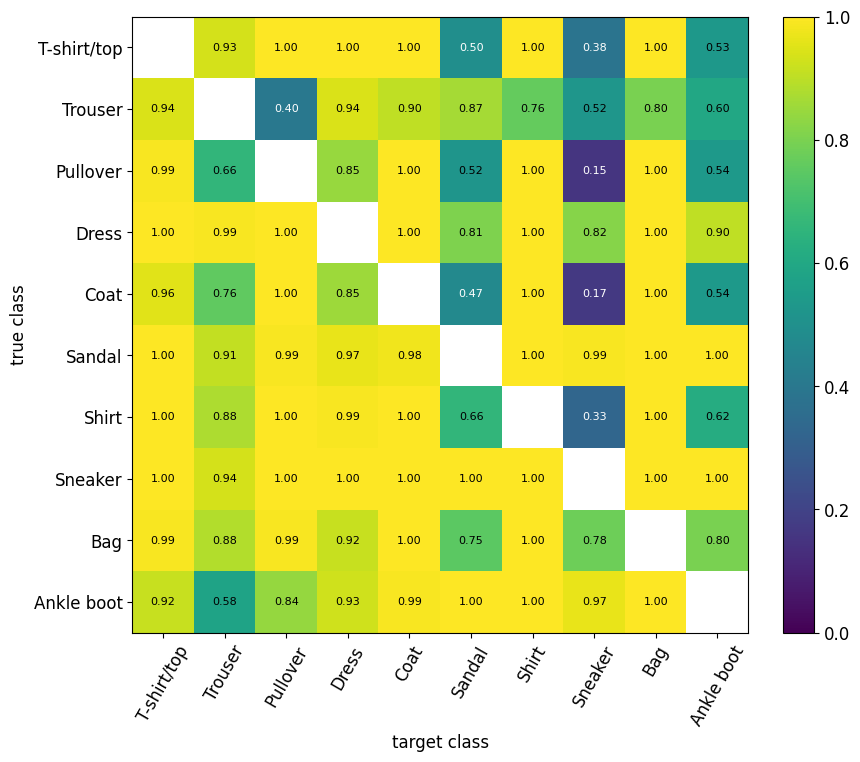

In [55]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Я получил несимметричную матрицу targeted success: средняя |S−Sᵀ| вне диагонали равна 0.193, максимум — 0.829. Строки соответствуют истинному классу, столбцы — цели; диагональ исключена.

Среди самых лёгких пар Ankle boot->Bag, Ankle boot->Shirt, Ankle boot->Sandal, Bag->Shirt и Bag->Coat: targeted success во всех случаях равен 100%. Самые трудные пары: Pullover->Sneaker — 17.1%, Coat->Sneaker — 17.4%, Shirt->Sneaker — 35.1%, Trouser->Pullover — 40.0%, T-shirt/top->Sneaker — 40.2%.

Для целей (y+1)%10 я получил hit rate 76.1%, хотя без атаки модель попадала в эти цели только в 0.5% случаев. Естественная путаница может облегчать некоторые переходы, но не объясняет всю матрицу: например, clean confusion для Ankle boot->Bag равна нулю при 100% успехе атаки. Несимметричность я связываю с различными границами решения, градиентами и распределениями входов для переходов s->t и t->s. Матрица включает все объекты исходного класса, в том числе clean-ошибки.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [56]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.** Я выбрал ветку targeted (5.2), поэтому transfer (5.3) не сделал

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [57]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [58]:
def adversarial_train(model,eps,attack,epochs=AT_EPOCHS,lr=1e-3,log=True):
    # ваш код
    model=model.to(device);history=dict(clean=[],fgsm=[],pgd=[])
    opt=torch.optim.Adam(model.parameters(),lr=lr)
    for epoch in range(epochs):
        for x,y in iterate_batches(XF_train,YF_train,128):
            model.eval();adv=attack(model,x,y,eps).detach()
            model.train();opt.zero_grad(set_to_none=True)
            F.cross_entropy(model(adv),y).backward();opt.step()
        model.eval();model.zero_grad(set_to_none=True)
        history['clean'].append(attack_accuracy(model,XF_test[:1000],YF_test[:1000]))
        history['fgsm'].append(attack_accuracy(model,XF_test[:1000],YF_test[:1000],fgsm_attack,eps=eps))
        history['pgd'].append(attack_accuracy(model,XF_test[:1000],YF_test[:1000],pgd,eps=eps))
        if log:print(f'epoch {epoch+1}/{epochs}: clean={history["clean"][-1]:.3f}, FGSM={history["fgsm"][-1]:.3f}, PGD={history["pgd"][-1]:.3f}',flush=True)
    model.eval();model.zero_grad(set_to_none=True)
    return history

In [59]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1/5: clean=0.805, FGSM=0.699, PGD=0.661
epoch 2/5: clean=0.823, FGSM=0.701, PGD=0.663
epoch 3/5: clean=0.822, FGSM=0.723, PGD=0.697
epoch 4/5: clean=0.832, FGSM=0.720, PGD=0.693
epoch 5/5: clean=0.842, FGSM=0.751, PGD=0.721


In [60]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.918   0.118   0.005   0.000   0.000   0.000
PGD-AT       0.842   0.789   0.720   0.475   0.135   0.001


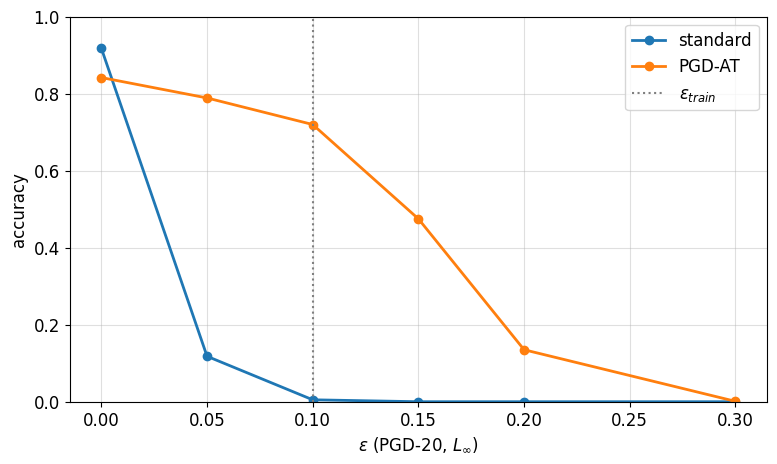

In [61]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Я получил clean accuracy 91.8% у обычной модели и 84.2% у PGD-AT: робастность стоила 7.6 п.п. чистой точности. При радиусе обучения $\varepsilon_{\text{train}}=0.1$ PGD-20 accuracy выросла с 0.5% до 72.0%. За пределами обучающего радиуса защита быстро ослабевает:

| ε | Обычная модель, PGD-20 | PGD-AT, PGD-20 |
|---:|---:|---:|
| 0 | 91.8% | 84.2% |
| 0.05 | 11.8% | 78.9% |
| 0.1 | 0.5% | 72.0% |
| 0.15 | 0.0% | 47.5% |
| 0.2 | 0.0% | 13.5% |
| 0.3 | 0.0% | 0.1% |

При увеличении ε с 0.1 до 0.2 accuracy PGD-AT снизилась с 72.0% до 13.5%, а при ε=0.3 составила 0.1%. Поэтому в моём опыте обучение при ε=0.1 не обеспечило устойчивости к существенно более сильным возмущениям.

Для PGD-7 training я выполнял семь forward и backward по входу для построения атаки, затем один forward/backward по параметрам модели. Получается восемь пар forward/backward на батч против одной при обычном обучении. Это не означает ровно восьмикратное увеличение времени: backward по входу и по параметрам имеют разную вычислительную стоимость, а оценки после эпох также требуют времени.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [62]:
def sanity_checks(model,x,y,eps):
    # ваш код
    model.eval();counts=dict(fgsm=0,pgd20=0,pgd100_x5=0,eps_1=0)
    for start in range(0,len(x),128):
        xb,yb=x[start:start+128],y[start:start+128]
        with torch.no_grad():clean=model(xb).argmax(1)==yb
        for key,attack,kwargs in [('fgsm',fgsm_attack,dict(eps=eps)),
                                  ('pgd20',pgd,dict(eps=eps,steps=20)),
                                  ('eps_1',pgd,dict(eps=1.,steps=20))]:
            adv=attack(model,xb,yb,**kwargs)
            with torch.no_grad():counts[key]+=(clean & (model(adv).argmax(1)==yb)).sum().item()
        survives=clean.clone()
        for _ in range(5):
            adv=pgd(model,xb,yb,eps=eps,steps=100)
            with torch.no_grad():survives &= model(adv).argmax(1)==yb
        counts['pgd100_x5']+=survives.sum().item()
    return {k:v/len(x) for k,v in counts.items()}

In [63]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.086      0.012      0.008      0.000
PGD-AT                      0.754      0.727      0.727      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** Я провёл sanity checks на первых 256 test-объектах. Clean-ошибки включены в итоговые ошибки; пять restarts объединены пересечением масок correct.

| Модель | FGSM | PGD-20 | PGD-100×5 | ε=1 |
|---|---:|---:|---:|---:|
| Обычная | 8.6% | 1.12% | 0.8% | 0% |
| PGD-AT | 75% | 72.7% | 72.7% | 0% |

Усиление PGD снизило accuracy обеих моделей. При ε=1 accuracy равна нулю. Я не увидел грубых противоречий этим проверкам, но они не доказывают отсутствие gradient masking. Отдельные конечные PGD-прогоны не обязаны быть строго упорядочены из-за random start.

Модель с высокой FGSM и почти нулевой PGD accuracy может пройти эти sanity checks: тогда её робастность к PGD низкая, даже если одноступенчатая атака выглядит слабой. Дополнительно я бы проверил другую сетку step sizes и независимую сильную атаку, например AutoAttack.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [64]:
def input_gradient(model, x, y):
    # ваш код
    model.eval()
    gradients = []
    for i in range(len(x)):
        xx = x[i:i+1].detach().clone().requires_grad_(True)
        with torch.enable_grad():
            logit = model(xx)[0, y[i]]
            grad, = torch.autograd.grad(logit, xx)
        gradients.append(grad.detach().abs())
    return torch.cat(gradients, dim=0) if gradients else torch.empty_like(x)

def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [65]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5911577343940735, 'PGD-AT': 0.2279316782951355}

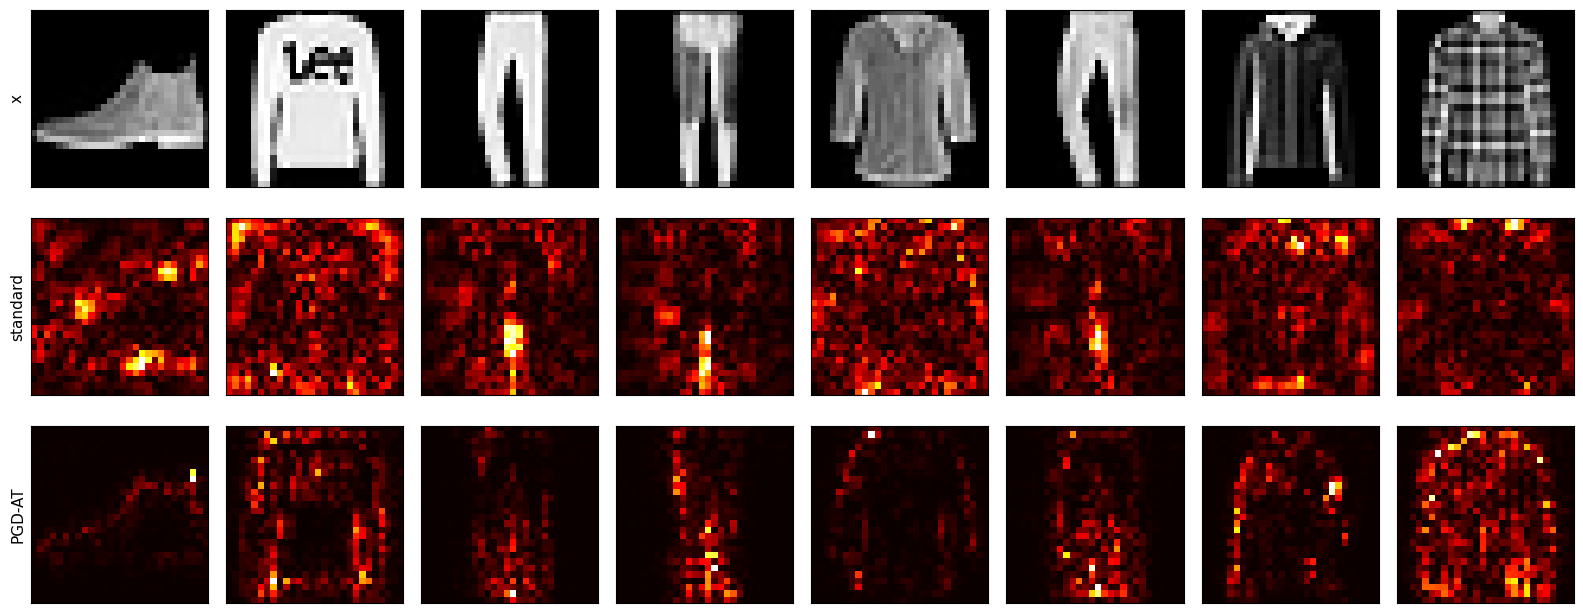

In [66]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** Я оценивал |∇x z_y|, то есть saliency по истинному логиту, а не градиент cross-entropy из FGSM. На первых 1000 test-объектах доля массы saliency на нулевом фоне составила 59% для обычной модели и 22% для PGD-AT. Сам фон занимает 49.83% пикселей.

На восьми картах у обычной модели я вижу яркие пятна вне силуэта: например, вокруг ботинка, ниже пуловера и по краям изображений. У PGD-AT активность чаще связана с деталями объекта: различимы полосы вдоль штанин и части контура одежды, а фон темнее. Эффект не одинаков для всех примеров: у ботинка PGD-AT-карта остаётся очень локальной и не воспроизводит весь силуэт.

Это согласуется с PGD-20 accuracy при ε=0.1: 0.7% у обычной модели против 72.0% у PGD-AT. Однако saliency не является сертификатом робастности: цветовая шкала у каждой карты своя, восемь объектов могут быть нерепрезентативны, а гладкий или понятный градиент ещё не означает, что сильная атака не найдёт ошибку. Поэтому вывод я опираю также на количественные PGD-оценки и sanity checks.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [67]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [68]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        # ваш код
        return list(torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True))


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [69]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [70]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

EOS lr=0.01, step=0, loss=0.4973, lambda=4.439, 2/lr=200
EOS lr=0.01, step=50, loss=0.3623, lambda=4.501, 2/lr=200
EOS lr=0.01, step=100, loss=0.3192, lambda=4.709, 2/lr=200
EOS lr=0.01, step=150, loss=0.2937, lambda=4.875, 2/lr=200
EOS lr=0.01, step=200, loss=0.2756, lambda=5.074, 2/lr=200
EOS lr=0.01, step=250, loss=0.2622, lambda=5.3, 2/lr=200
EOS lr=0.01, step=300, loss=0.252, lambda=5.533, 2/lr=200
EOS lr=0.01, step=350, loss=0.2442, lambda=5.76, 2/lr=200
EOS lr=0.01, step=400, loss=0.2379, lambda=5.971, 2/lr=200
EOS lr=0.01, step=450, loss=0.2327, lambda=6.161, 2/lr=200
EOS lr=0.01, step=500, loss=0.2282, lambda=6.33, 2/lr=200
EOS lr=0.01, step=550, loss=0.2244, lambda=6.479, 2/lr=200
EOS lr=0.01, step=600, loss=0.221, lambda=6.61, 2/lr=200
EOS lr=0.01, step=650, loss=0.218, lambda=6.727, 2/lr=200
EOS lr=0.01, step=700, loss=0.2152, lambda=6.833, 2/lr=200
EOS lr=0.01, step=750, loss=0.2127, lambda=6.931, 2/lr=200
EOS lr=0.01, step=800, loss=0.2103, lambda=7.023, 2/lr=200
EOS lr=0

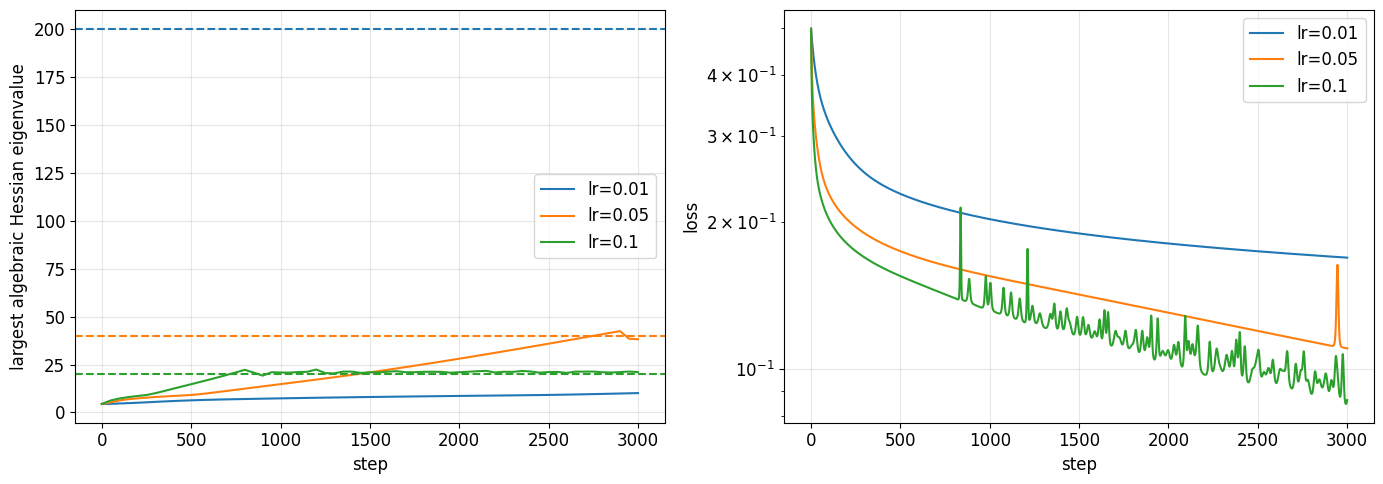

In [71]:
# ваш код
if '7.1' in BONUS_TASKS:
    EOS_LRS=[0.01,0.05,0.1]
    eos_runs={}
    for eta in EOS_LRS:
        model=make_tanh_mlp(0);params=list(model.parameters())
        opt=torch.optim.SGD(params,lr=eta)
        hist=dict(loss=[],sharpness=[],sharpness_steps=[])
        v=None;started=time.perf_counter()
        for step in range(EOS_STEPS+1):
            loss=mse_loss(model)
            hist['loss'].append(loss.item())
            if step%50==0:
                lam,v=top_eigenvalue(lambda:mse_loss(model),params,iters=20,v=v)
                hist['sharpness'].append(lam);hist['sharpness_steps'].append(step)
                print(f'EOS lr={eta}, step={step}, loss={loss.item():.4g}, lambda={lam:.4g}, 2/lr={2/eta:.4g}',flush=True)
            if step<EOS_STEPS:
                opt.zero_grad();loss.backward();opt.step()
        eos_runs[eta]=hist
        RUN_TIMES[f'eos_{eta}_seconds']=time.perf_counter()-started
        del model,params,opt
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    for eta,hist in eos_runs.items():
        line,=axes[0].plot(hist['sharpness_steps'],hist['sharpness'],label=f'lr={eta}')
        axes[0].axhline(2/eta,color=line.get_color(),linestyle='--')
        axes[1].semilogy(hist['loss'],label=f'lr={eta}')
    axes[0].set_ylabel('largest algebraic Hessian eigenvalue');axes[1].set_ylabel('loss')
    for ax in axes:ax.set_xlabel('step');ax.legend();ax.grid(alpha=.3)
    plt.tight_layout();plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** Я провёл по 3000 full-batch GD шагов для каждого η, измеряя sharpness каждые 50 шагов.

| η | Loss: начало -> конец | λ_max в конце | 2/η | Первое попадание в ±20% от границы, шаг |
|---:|---:|---:|---:|---:|
| 0.01 | 0.4973 -> 0.1690 | 10.1 | 200 | Не было |
| 0.05 | 0.4973 -> 0.1101 | 38.17 | 40 | 2300 |
| 0.1 | 0.4973 -> 0.08633 | 21.04 | 20 | 600 |

При η=0.01 sharpness постепенно росла, но до границы 200 не приблизилась: в конце она составила 10.1. Loss снижался на всех сохранённых замерах.

При η=0.05 sharpness приблизилась к границе 40, достигла 42.43 на шаге 2900 и затем снизилась до 38.17. Одновременно loss стал немонотонным: на шагах 2900 -> 2950 -> 3000 он изменился как 0.1117 -> 0.1436 -> 0.1101.

При η=0.1 sharpness приблизилась к границе 20 раньше, а затем колебалась около неё. Loss также колебался, но в целом снизился с 0.4973 до 0.08633. Порог ±20% я использую только как явный способ описать близость к границе, а не как доказательство edge of stability.

Критерий $0 < \eta < 2/\lambda_{\max}$ получен для фиксированной положительно определённой квадратичной функции. У нелинейной сети Hessian меняется по траектории и может иметь собственные числа разных знаков. Кроме того, Lanczos даёт приближённую оценку sharpness, а измерения раз в 50 шагов могут пропускать быстрые изменения. Поэтому я не рассматриваю локальную квадратичную границу как общую гарантию поведения нелинейной сети.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [72]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x,weight,bias=None,stride=1,padding=0,groups=1):
        # ваш код
        B,C,H,W=x.shape;O,CG,kh,kw=weight.shape
        if groups<=0 or C%groups or O%groups or CG!=C//groups:raise ValueError('Invalid groups')
        xp=F.pad(x,(padding,padding,padding,padding))
        hp,wp=xp.shape[-2:];fft_size=(hp+kh-1,wp+kw-1)
        xf=torch.fft.rfft2(xp,s=fft_size).reshape(B,groups,CG,fft_size[0],-1)
        wf=torch.fft.rfft2(weight.flip((-2,-1)),s=fft_size).reshape(groups,O//groups,CG,fft_size[0],-1)
        yf=torch.einsum('bgchw,gochw->bgohw',xf,wf)
        full=torch.fft.irfft2(yf,s=fft_size).reshape(B,O,*fft_size)
        out=full[:,:,kh-1:hp:stride,kw-1:wp:stride]
        return out if bias is None else out+bias[None,:,None,None]

In [73]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** Я вычислял полное valid-поле, а затем оставлял позиции с шагом s. На больших картах остаётся примерно 1/s² выходов, поэтому выбрасывается 1−1/s²: около 75% при s=2 и 88.9% при s=3. Точная доля равна 1−ceil(H_valid/s)·ceil(W_valid/s)/(H_valid·W_valid) и зависит от краёв. FFT может быть выгоднее на больших ядрах и картах, если экономия арифметики компенсирует преобразования, буферы и вычисление неиспользуемых позиций.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [74]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M,steps=5,coeffs=(3.4445,-4.7750,2.0315)):
        # ваш код
        if M.ndim!=2:raise ValueError('Expected a matrix')
        transposed=M.shape[0]>M.shape[1]
        X=M.T if transposed else M
        X=X/X.norm().clamp_min(1e-7)
        a,b,c=coeffs
        for _ in range(steps):
            A=X@X.T
            X=a*X+(b*A+c*(A@A))@X
        return X.T if transposed else X

    class ConvMuon(torch.optim.Optimizer):
        def __init__(self,params,lr=0.02,momentum=0.95):
            super().__init__(params,dict(lr=lr,momentum=momentum))
        @torch.no_grad()
        def step(self):
            # ваш код
            for group in self.param_groups:
                mu=group['momentum']
                for p in group['params']:
                    if p.grad is None:continue
                    if p.ndim<2:raise ValueError('Muon requires ndim >= 2')
                    state=self.state[p]
                    if not state:state['momentum_buffer']=torch.zeros_like(p)
                    buf=state['momentum_buffer'];buf.lerp_(p.grad,1-mu)
                    U=(1-mu)*p.grad+mu*buf
                    m=p.shape[0];n=p.numel()//m
                    update=newton_schulz(U.reshape(m,n))
                    p.add_(update.reshape_as(p),alpha=-group['lr']*math.sqrt(max(1,m/n)))

In [75]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [76]:
# ваш код
if '7.3' in BONUS_TASKS:
    MUON_LR=0.02
    set_seed(0);muon_model=ResNetCIFAR(20).to(device)
    conv_params=[p for p in muon_model.parameters() if p.ndim==4]
    rest=[p for p in muon_model.parameters() if p.ndim!=4]
    opt_m=ConvMuon(conv_params,lr=MUON_LR)
    opt_a=MyAdamW([dict(params=[p for p in rest if p.ndim>1],weight_decay=.05),
                   dict(params=[p for p in rest if p.ndim<=1],weight_decay=0.)],lr=LR)
    total=EPOCHS*math.ceil(len(X_train)/256)
    schedulers=[torch.optim.lr_scheduler.LambdaLR(opt,lambda t:cosine_lr(t,total)) for opt in (opt_m,opt_a)]
    hist_muon=dict(train_loss=[],test_acc=[]);started=time.perf_counter()
    for epoch in range(EPOCHS):
        muon_model.train();loss_sum=0.
        for x,y in iterate_batches(X_train,Y_train,256):
            opt_m.zero_grad(set_to_none=True);opt_a.zero_grad(set_to_none=True)
            loss=F.cross_entropy(muon_model(normalize(x)),y);loss.backward()
            opt_m.step();opt_a.step()
            for scheduler in schedulers:scheduler.step()
            loss_sum+=loss.item()*len(x)
        hist_muon['train_loss'].append(loss_sum/len(X_train))
        hist_muon['test_acc'].append(accuracy(predict_logits(muon_model,X_test,transform=normalize),Y_test))
        print(f'Muon epoch {epoch+1}: loss={hist_muon["train_loss"][-1]:.4f}, test={hist_muon["test_acc"][-1]:.4f}',flush=True)
    RUN_TIMES['cifar_muon_seconds']=time.perf_counter()-started
    hist_adamw=history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name,hist in [('AdamW',hist_adamw),('Muon',hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

Muon epoch 1: loss=1.1671, test=0.6496
Muon epoch 2: loss=0.6748, test=0.7416
Muon epoch 3: loss=0.5129, test=0.7760
Muon epoch 4: loss=0.4045, test=0.8074
Muon epoch 5: loss=0.3216, test=0.8133
Muon epoch 6: loss=0.2436, test=0.7967
Muon epoch 7: loss=0.1809, test=0.8308
Muon epoch 8: loss=0.1304, test=0.8255
Muon epoch 9: loss=0.0919, test=0.8339
Muon epoch 10: loss=0.0621, test=0.8327
Muon epoch 11: loss=0.0423, test=0.8386
Muon epoch 12: loss=0.0283, test=0.8381
Muon epoch 13: loss=0.0171, test=0.8412
Muon epoch 14: loss=0.0104, test=0.8435
Muon epoch 15: loss=0.0057, test=0.8466
Muon epoch 16: loss=0.0033, test=0.8467
Muon epoch 17: loss=0.0018, test=0.8481
Muon epoch 18: loss=0.0010, test=0.8489
Muon epoch 19: loss=0.0008, test=0.8509
Muon epoch 20: loss=0.0007, test=0.8506
            train loss  test acc
AdamW           0.0118    0.8253
Muon            0.0007    0.8506


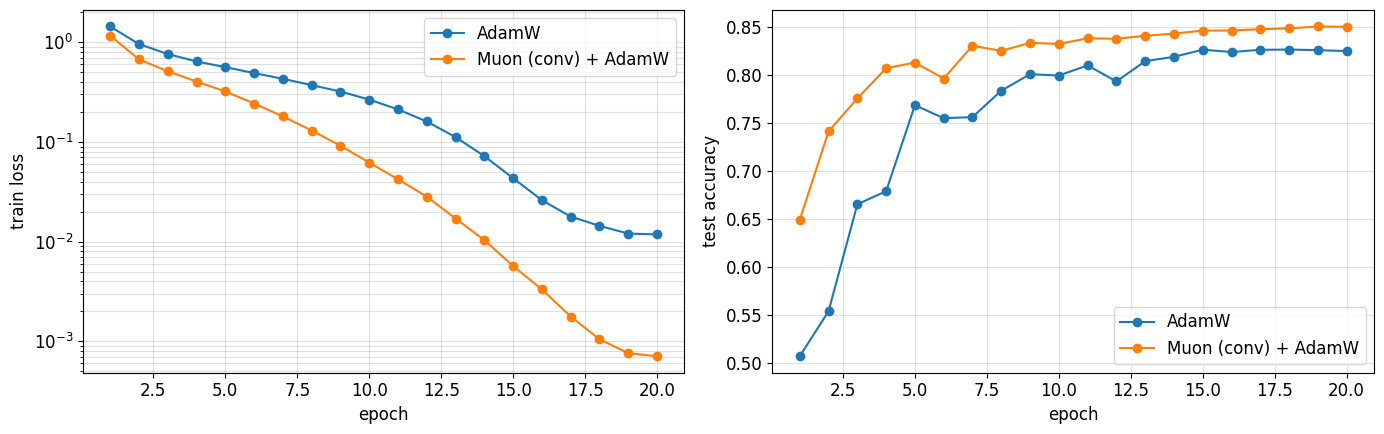

In [77]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** Я сравнил AdamW и ConvMuon+AdamW при одинаковом бюджете в 20 эпох.

| Оптимизатор | Final train loss | Final test accuracy |
|---|---:|---:|
| AdamW | 0.0118 | 82.53% |
| ConvMuon+AdamW | 0.0007 | 85.06% |

При том же числе эпох гибрид получил меньший final train loss и преимущество test accuracy 2.53 п.п. Для вывода о том, какой оптимизатор быстрее снижает loss в ходе обучения, нужно сравнить обе кривые по эпохам: одних конечных значений недостаточно.

У AdamW хранятся два момента на каждый скалярный параметр — первый и второй; у ConvMuon один буфер momentum. При float32 это соответственно 8 и 4 байта на параметр, без учёта весов, градиентов, служебных счётчиков и временных матриц Newton–Schulz. В гибриде свёрточные веса используют ConvMuon, а BatchNorm и голова — AdamW.

Я сравниваю два фиксированных рецепта обучения с разными lr и weight decay для свёрток, поэтому этот опыт не позволяет выделить влияние одного только алгоритма оптимизации.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [78]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [79]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.922, 'L0, k=5': 0.638}
standard    0.922  0.886  0.850  0.784  0.638  0.398  0.146  0.030
PGD-AT      0.854  0.818  0.780  0.764  0.720  0.626  0.424  0.298


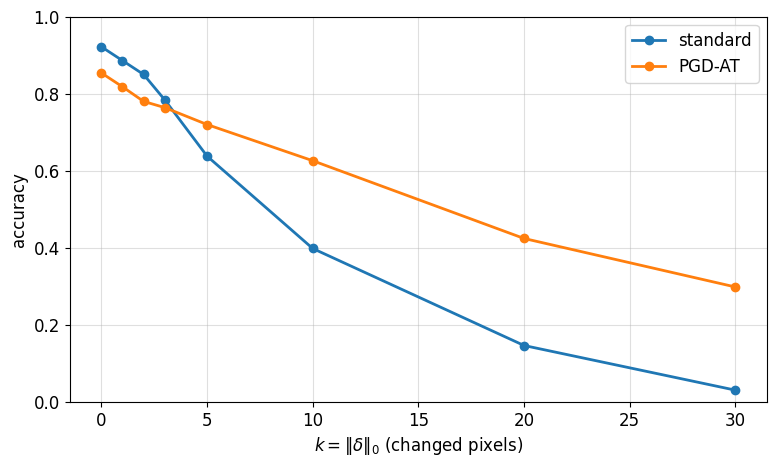

In [80]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** Я получил следующие accuracy на первых 500 test-объектах:

| k | Обычная модель | PGD-AT |
|---:|---:|---:|
| 0 | 92.2% | 85.4% |
| 1 | 88.6% | 81.8% |
| 2 | 85.0% | 78.0% |
| 3 | 78.4% | 76.4% |
| 5 | 63.8% | 72.0% |
| 10 | 39.8% | 62.6% |
| 20 | 14.6% | 42.4% |
| 30 | 3.0% | 29.8% |

При k=1–3 обычная модель имеет более высокую абсолютную accuracy, что нужно сопоставлять с её лучшим clean baseline. При k≥5 преимущество получает PGD-AT. Например, при k=30 accuracy составляет 29.8% против 3.0%, а падение относительно собственного clean baseline — 55.6 и 89.2 п.п. соответственно. В моём опыте $L_\infty$-обучение помогло против больших бюджетов этой жадной $L_0$-атаки, но не дало полной защиты.

$L_\infty$-шар с $\varepsilon=0.1$ запрещает изменение любого пикселя больше чем на 0.1, тогда как изменение 0 -> 1 имеет $L_\infty$-норму 1 при $L_0=1$. Поэтому такая угроза лежит вне обучающего $L_\infty$-шара. Кроме того, жадная атака не гарантирует нахождения всех успешных возмущений; результат не является сертификатом $L_0$-робастности.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [81]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
epoch 1/5: clean=0.739, FGSM=0.637, PGD=0.046
epoch 2/5: clean=0.582, FGSM=0.906, PGD=0.000
epoch 3/5: clean=0.441, FGSM=0.947, PGD=0.000
epoch 4/5: clean=0.541, FGSM=0.963, PGD=0.000
epoch 5/5: clean=0.535, FGSM=0.991, PGD=0.000
FGSM-RS
epoch 1/5: clean=0.767, FGSM=0.617, PGD=0.374
epoch 2/5: clean=0.789, FGSM=0.646, PGD=0.401
epoch 3/5: clean=0.791, FGSM=0.717, PGD=0.421
epoch 4/5: clean=0.800, FGSM=0.708, PGD=0.437
epoch 5/5: clean=0.808, FGSM=0.746, PGD=0.387


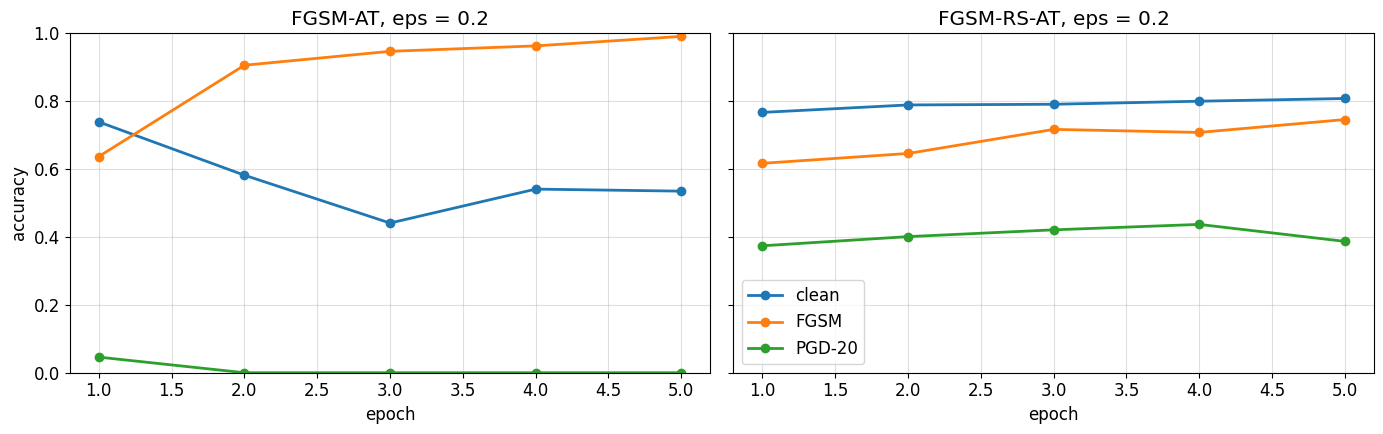

In [82]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [83]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.5390625, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.74609375, 'pgd20': 0.37890625, 'pgd100_x5': 0.3046875, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** У FGSM-модели PGD-20 accuracy уже после первой эпохи равна 4.6%, а после второй падает до 0.0% и остаётся нулевой. При этом FGSM accuracy растёт с 63.7% до 99.1%. Это большой разрыв между результатами одноступенчатой и многошаговой атак, совместимый с catastrophic overfitting. Падение PGD accuracy между первой и второй эпохами есть, но перехода от высокой робастности к почти нулевой я не наблюдал: первая измеренная PGD accuracy уже низкая. Поэтому точный момент возникновения эффекта по оценкам только после эпох установить нельзя.

| Эпоха | FGSM-AT: FGSM | FGSM-AT: PGD-20 | FGSM-RS-AT: FGSM | FGSM-RS-AT: PGD-20 |
|---:|---:|---:|---:|---:|
| 1 | 63.7% | 4.6% | 61.7% | 37.4% |
| 2 | 90.6% | 0.0% | 64.6% | 40.1% |
| 3 | 94.7% | 0.0% | 71.7% | 42.1% |
| 4 | 96.3% | 0.0% | 70.8% | 43.7% |
| 5 | 99.1% | 0.0% | 74.6% | 38.7% |

Random start заметно изменил картину: PGD-20 accuracy оставалась в диапазоне 37.4–43.7%, без спада к нулю. На пятой эпохе она снизилась с 43.7% до 38.7%, то есть на 5.0 п.п.

Усиленная проверка на первых 256 test-объектах дала следующие результаты:

| Модель | FGSM | PGD-20 | PGD-100 × 5 рестартов | PGD при ε=1 |
|---|---:|---:|---:|---:|
| FGSM-AT | 53.91% | 0.00% | 0.00% | 0.00% |
| FGSM-RS-AT | 74.61% | 37.89% | 30.47% | 0.00% |

Я считаю защиту обычной FGSM-модели от PGD фактически отсутствующей. У FGSM-RS сохраняется ненулевая робастность, но усиление атаки снижает её оценку с 37.89% до 30.47%. Следовательно, random start помог в этом прогоне, но не обеспечил полной защиты.

В таблице по эпохам приведены оценки из кривых обучения. Sanity checks дополнительно учитывают clean-ошибки и используют меньший срез test, поэтому их FGSM accuracy отличается.

В следующем отдельном опыте я бы проверил гипотезу о зависимости эффекта от lr: оставил бы те же данные, ε=0.2 и пять эпох, но выбрал другой фиксированный lr и измерял PGD accuracy чаще внутри первой эпохи.